In [1]:
import torch
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

PyTorch: 2.11.0+cu128
GPU available: True
GPU: Tesla T4


In [3]:
import torch, torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"

# 70,000 handwritten digits, 28x28 greyscale. The "hello world" of this field.
tf = transforms.ToTensor()
train_ds = datasets.MNIST("/kaggle/working/data", train=True,  download=True, transform=tf)
test_ds  = datasets.MNIST("/kaggle/working/data", train=False, download=True, transform=tf)

train_dl = DataLoader(train_ds, batch_size=128, shuffle=True)
test_dl  = DataLoader(test_ds,  batch_size=256)

model = nn.Sequential(
    nn.Flatten(),              # 28x28 image -> a flat row of 784 numbers
    nn.Linear(784, 256),       # 784 inputs -> 256 neurons
    nn.ReLU(),                 # the "bend" - without this, the whole net collapses to one layer
    nn.Linear(256, 10),        # 256 -> 10 outputs, one score per digit
).to(device)

opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()

for epoch in range(3):
    model.train()
    for images, labels in train_dl:
        images, labels = images.to(device), labels.to(device)

        logits = model(images)           # forward pass: what does it think?
        loss = loss_fn(logits, labels)   # how wrong was it? one number

        opt.zero_grad()                  # clear last step's gradients
        loss.backward()                  # BACKPROPAGATION - gradient for every weight
        opt.step()                       # nudge every weight slightly

    model.eval()
    correct = 0
    with torch.no_grad():
        for images, labels in test_dl:
            images, labels = images.to(device), labels.to(device)
            correct += (model(images).argmax(1) == labels).sum().item()
    print(f"epoch {epoch+1}  test accuracy {correct/len(test_ds):.4f}")

epoch 1  test accuracy 0.9439
epoch 2  test accuracy 0.9641
epoch 3  test accuracy 0.9698


sigmoid   layer 1: 1.985e-19   last layer: 1.376e-02   ratio: 69,348,895,112,929,808x
relu      layer 1: 8.132e-11   last layer: 6.676e-04   ratio: 8,209,715x


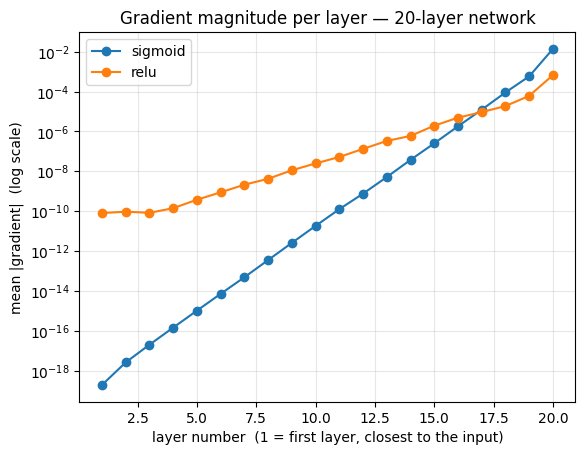

In [3]:
import torch, torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
train_dl = DataLoader(
    datasets.MNIST("/kaggle/working/data", train=True, download=True,
                   transform=transforms.ToTensor()),
    batch_size=128, shuffle=True)

def make_net(depth, activation):
    """A network `depth` layers deep, all the same width."""
    layers = [nn.Flatten(), nn.Linear(784, 128), activation()]
    for _ in range(depth - 2):
        layers += [nn.Linear(128, 128), activation()]
    layers += [nn.Linear(128, 10)]
    return nn.Sequential(*layers).to(device)

def gradient_profile(depth, activation):
    """One batch, one backward pass. How big is the gradient at each layer?"""
    model = make_net(depth, activation)
    images, labels = next(iter(train_dl))
    images, labels = images.to(device), labels.to(device)

    loss = nn.CrossEntropyLoss()(model(images), labels)
    model.zero_grad()
    loss.backward()

    return [m.weight.grad.abs().mean().item()
            for m in model if isinstance(m, nn.Linear)]

for name, act in [("sigmoid", nn.Sigmoid), ("relu", nn.ReLU)]:
    g = gradient_profile(20, act)
    print(f"{name:8s}  layer 1: {g[0]:.3e}   last layer: {g[-1]:.3e}   "
          f"ratio: {g[-1]/g[0]:,.0f}x")
    plt.semilogy(range(1, len(g) + 1), g, marker="o", label=name)

plt.xlabel("layer number  (1 = first layer, closest to the input)")
plt.ylabel("mean |gradient|  (log scale)")
plt.title("Gradient magnitude per layer — 20-layer network")
plt.legend(); plt.grid(True, alpha=0.3)
plt.savefig("/kaggle/working/grad_profile_20layer.png", dpi=150, bbox_inches="tight")
plt.show()